# 05 — Figures and tables for the project report

This notebook regenerates the figures, tables and quoted numbers in the GridSense project report that are not written directly by `backend/train.py`: the exploratory data analysis (Chapter 3), the pipeline diagram (Chapter 4), the fitted trend (Chapter 5), the backtest analysis, band coverage, error analysis and ablation study (Chapter 6), and the SHAP explanations (Chapter 7).

It reuses the project's own code rather than re-implementing it. `backend/features.py` provides the trend and feature logic. `backend/train.py` provides the rolling-origin backtest, the baselines, the metrics and the band calibration. The SHAP section uses the deployed model in `models/point_model.json`.

**How to run.** From the `notebooks/` folder, with the packages in `requirements.txt` (plus `matplotlib` and `jupyter` from `requirements-dev.txt`). It reads only committed files and does not overwrite anything in `models/` or `data/`. Figures are saved to `notebooks/figures/`. The full run takes several minutes on a laptop CPU, mostly for the backtest and the ablation study. Every model uses `random_state=42`.

Figure and table numbers follow the final version of the report.

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import xgboost as xgb
warnings.filterwarnings("ignore", message="IProgress not found")
import shap

# Repository root, whether the notebook is started from notebooks/ or from the root
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "backend"))

import features as F   # trend and feature logic shared by training and serving
import train           # backtest, baselines, metrics, band calibration

FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(exist_ok=True)
SEED = 42

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "figure.dpi": 110,
})
REGIONS = ["National", "Northern", "Western", "Eastern", "Southern", "North-Eastern"]
REGION_COLORS = {"National": "black", "Northern": "#d55e00", "Western": "#1f77b4",
                 "Eastern": "#009e73", "Southern": "#e7298a", "North-Eastern": "#7570b3"}

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")

df = train.load_data()   # data/processed/merged.parquet plus hour, day_of_week, month
print(f"{len(df):,} rows, {df['location'].nunique()} series, {df['datetime'].min()} to {df['datetime'].max()}")

280,368 rows, 6 series, 2019-01-01 00:00:00 to 2024-04-30 23:00:00


## Chapter 3 — Dataset description and exploratory data analysis

### Table 2: variable ranges

In [2]:
print(f"Hourly timestamps: {df['datetime'].nunique():,} ({df['datetime'].dt.date.nunique():,} days)")
print(f"demand_gw:   {df['demand_gw'].min():.2f} to {df['demand_gw'].max():.2f} GW")
print(f"temperature: {df['temperature'].min():.1f} to {df['temperature'].max():.1f} °C")
print(f"humidity:    {df['humidity'].min():.0f} to {df['humidity'].max():.0f} %")
holiday_days = df.loc[df["is_holiday"] == 1, "datetime"].dt.date.nunique()
holiday_rows = int(df["is_holiday"].sum())
print(f"is_holiday:  {holiday_days} days, {holiday_rows:,} of {len(df):,} rows ({holiday_rows / len(df):.2%})")

Hourly timestamps: 46,728 (1,947 days)
demand_gw:   0.57 to 237.36 GW
temperature: 2.0 to 45.4 °C
humidity:    7 to 100 %
is_holiday:  97 days, 13,968 of 280,368 rows (4.98%)


### Table 3: summary statistics of hourly demand (GW)

In [3]:
table3 = df.groupby("location")["demand_gw"].agg(["mean", "std", "min", "median", "max"]).loc[REGIONS]
table3["share of national mean (%)"] = table3["mean"] / table3.loc["National", "mean"] * 100
table3.round(2)

,mean,std,min,median,max,share of national mean (%)
location,,,,,,
National,160.49,23.10,95.34,159.54,237.36,100.00
Northern,47.91,10.50,19.22,47.52,80.79,29.86
Western,50.40,8.00,28.11,50.04,73.02,31.41
Eastern,18.57,3.33,9.26,18.43,28.86,11.57
Southern,41.59,7.47,23.19,40.68,68.21,25.91
North-Eastern,2.01,0.44,0.57,1.97,3.59,1.25


### Section 3.3: data quality checks

In [4]:
wide = df.pivot(index="datetime", columns="location", values="demand_gw")
expected = pd.date_range(wide.index.min(), wide.index.max(), freq="h")
print("Missing hourly timestamps:", len(expected.difference(wide.index)))
print("Duplicate (datetime, location) rows:", int(df.duplicated(["datetime", "location"]).sum()))
print("Missing values:", int(df[["demand_gw", "temperature", "humidity"]].isna().sum().sum()))
print("Zero or negative demand:", int((df["demand_gw"] <= 0).sum()))

ratio = wide.drop(columns="National").sum(axis=1) / wide["National"]
print(f"Sum of regions / National: min {ratio.min():.4f}, max {ratio.max():.4f}")

print("\nOutliers by the 1.5 x IQR rule (low, high):")
for loc in REGIONS:
    s = df.loc[df["location"] == loc, "demand_gw"]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    print(f"  {loc:14s} {int((s < q1 - 1.5 * iqr).sum()):4d} {int((s > q3 + 1.5 * iqr).sum()):4d}")

Missing hourly timestamps: 0
Duplicate (datetime, location) rows: 0
Missing values: 0
Zero or negative demand: 0
Sum of regions / National: min 1.0000, max 1.0000

Outliers by the 1.5 x IQR rule (low, high):
  National          9   67
  Northern          0   42
  Western           0    0
  Eastern           0   59
  Southern          0  632
  North-Eastern    30  282


#### Additional check: repeated demand values

It looks for days whose demand values repeat an earlier day exactly. In the source dataset, demand for 1–30 April 2024 repeats 1–30 March 2024 for the Northern, Western, Eastern and Southern regions (and almost exactly for National and North-Eastern), and 7 November 2022 repeats 6 November 2022. The weather data for those dates is genuine. The results in the report were computed on the data as distributed, so April 2024 errors partly reflect this defect rather than model behaviour (report Sections 3.3 and 6.4).

In [5]:
march = wide.loc["2024-03-01":"2024-03-30 23:00"].to_numpy()
april = wide.loc["2024-04-01":"2024-04-30 23:00"].to_numpy()
nov6, nov7 = wide.loc["2022-11-06"].to_numpy(), wide.loc["2022-11-07"].to_numpy()
pd.DataFrame({
    "max |Apr 1-30 2024 - Mar 1-30 2024| (GW)": np.abs(april - march).max(axis=0),
    "max |7 Nov 2022 - 6 Nov 2022| (GW)": np.abs(nov7 - nov6).max(axis=0),
}, index=wide.columns).loc[REGIONS].round(4)

,max |Apr 1-30 2024 - Mar 1-30 2024| (GW),max |7 Nov 2022 - 6 Nov 2022| (GW)
location,,
National,0.1865,0.0447
Northern,0.0000,0.0000
Western,0.0000,0.0390
Eastern,0.0000,0.0000
Southern,0.0000,0.0000
North-Eastern,0.1865,0.0199


### Section 3.4 and Figure 1: growth and the 2020 lockdown

National annual mean (GW): {2019: 146.8, 2020: 142.0, 2021: 156.3, 2022: 168.9, 2023: 180.8, 2024: 183.8}
Compound growth 2019-2023: 5.3% per year
April 2019: 154.3 GW, April 2020: 116.5 GW (-24%)


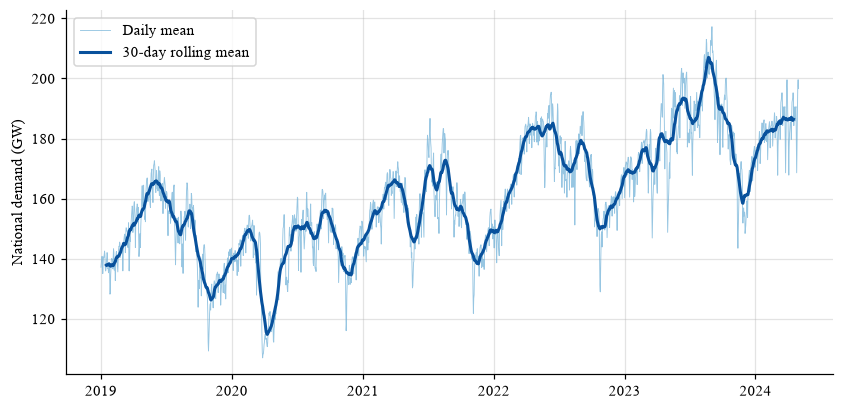

In [6]:
national = wide["National"]
annual = national.groupby(national.index.year).mean()
print("National annual mean (GW):", annual.round(1).to_dict())
print(f"Compound growth 2019-2023: {(annual[2023] / annual[2019]) ** (1 / 4) - 1:.1%} per year")
monthly = national.resample("MS").mean()
apr19, apr20 = monthly["2019-04"].iloc[0], monthly["2020-04"].iloc[0]
print(f"April 2019: {apr19:.1f} GW, April 2020: {apr20:.1f} GW ({apr20 / apr19 - 1:.0%})")

daily = national.resample("D").mean()
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.plot(daily.index, daily, color="#6baed6", lw=0.6, alpha=0.7, label="Daily mean")
ax.plot(daily.index, daily.rolling(30, center=True).mean(), color="#08519c", lw=2, label="30-day rolling mean")
ax.set_ylabel("National demand (GW)")
ax.legend(loc="upper left")
save(fig, "fig01_national_daily_demand.png")
plt.show()

### Figure 2: average hourly profile by region

National       peak 11:00, minimum  3:00, max/min 1.21
Northern       peak 19:00, minimum  3:00, max/min 1.22
Western        peak 11:00, minimum  3:00, max/min 1.19
Eastern        peak 19:00, minimum  6:00, max/min 1.18
Southern       peak 10:00, minimum  3:00, max/min 1.29
North-Eastern  peak 19:00, minimum  4:00, max/min 1.59
National weekend / weekday demand: 0.98


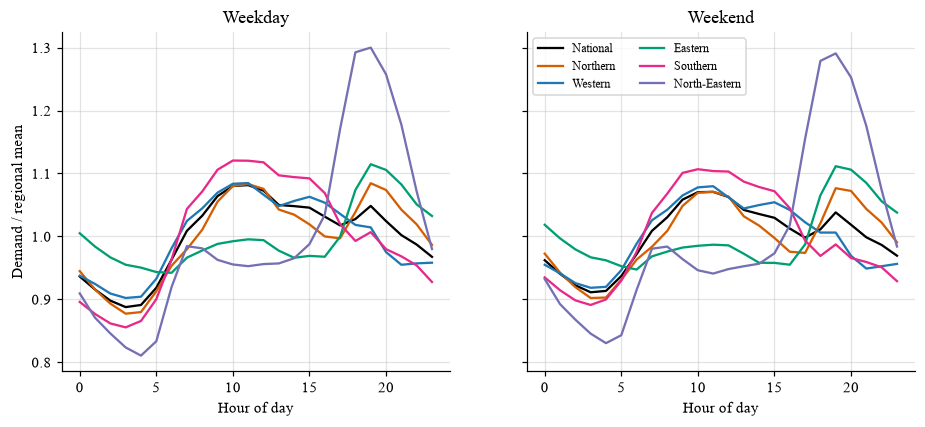

In [7]:
df["weekend"] = df["day_of_week"] >= 5
all_days = df.groupby(["location", "hour"])["demand_gw"].mean()
all_days = all_days / all_days.groupby(level=0).transform("mean")
for loc in REGIONS:
    p = all_days[loc]
    print(f"{loc:14s} peak {p.idxmax():2d}:00, minimum {p.idxmin():2d}:00, max/min {p.max() / p.min():.2f}")
nat = df[df["location"] == "National"]
print(f"National weekend / weekday demand: {nat.loc[nat['weekend'], 'demand_gw'].mean() / nat.loc[~nat['weekend'], 'demand_gw'].mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, weekend, title in [(axes[0], False, "Weekday"), (axes[1], True, "Weekend")]:
    profile = df[df["weekend"] == weekend].groupby(["location", "hour"])["demand_gw"].mean()
    profile = profile / profile.groupby(level=0).transform("mean")
    for loc in REGIONS:
        ax.plot(profile[loc].index, profile[loc].values, color=REGION_COLORS[loc], label=loc)
    ax.set_title(title)
    ax.set_xlabel("Hour of day")
axes[0].set_ylabel("Demand / regional mean")
axes[1].legend(ncol=2, fontsize=8)
save(fig, "fig02_hourly_profiles.png")
plt.show()

### Section 3.4: seasonality (monthly mean relative to the annual mean, 2019–2023)

In [8]:
to_2023 = df[df["datetime"].dt.year <= 2023]
monthly_mean = to_2023.groupby(["location", "month"])["demand_gw"].mean()
print("National monthly mean (GW):", monthly_mean["National"].round(1).to_dict())
relative = (monthly_mean / monthly_mean.groupby(level=0).transform("mean")).unstack()
relative.loc[REGIONS].round(2)

National monthly mean (GW): {1: 149.6, 2: 156.4, 3: 158.2, 4: 160.1, 5: 161.7, 6: 169.2, 7: 166.1, 8: 169.2, 9: 166.8, 10: 154.0, 11: 145.2, 12: 150.7}


month,1,2,3,4,5,6,7,8,9,10,11,12
location,,,,,,,,,,,,
National,0.94,0.98,1.00,1.01,1.02,1.06,1.05,1.06,1.05,0.97,0.91,0.95
Northern,0.88,0.87,0.83,0.88,1.01,1.20,1.22,1.23,1.19,0.95,0.83,0.90
Western,0.99,1.05,1.04,1.05,1.03,0.98,0.93,0.94,0.95,0.99,1.02,1.04
Eastern,0.86,0.88,0.95,1.04,1.04,1.11,1.14,1.12,1.12,1.02,0.87,0.85
Southern,0.98,1.09,1.16,1.09,1.00,0.99,0.94,0.99,0.97,0.93,0.90,0.94
North-Eastern,0.91,0.90,0.90,0.89,0.94,1.05,1.14,1.20,1.18,1.06,0.91,0.91


### Section 3.4 and Figure 3: demand versus temperature; holiday effect

Pearson correlation, demand vs temperature: {'National': 0.38, 'Northern': 0.53, 'Western': 0.32, 'Eastern': 0.44, 'Southern': 0.35, 'North-Eastern': 0.41}
Holiday / comparable non-holiday demand: 0.98 (97 holidays)


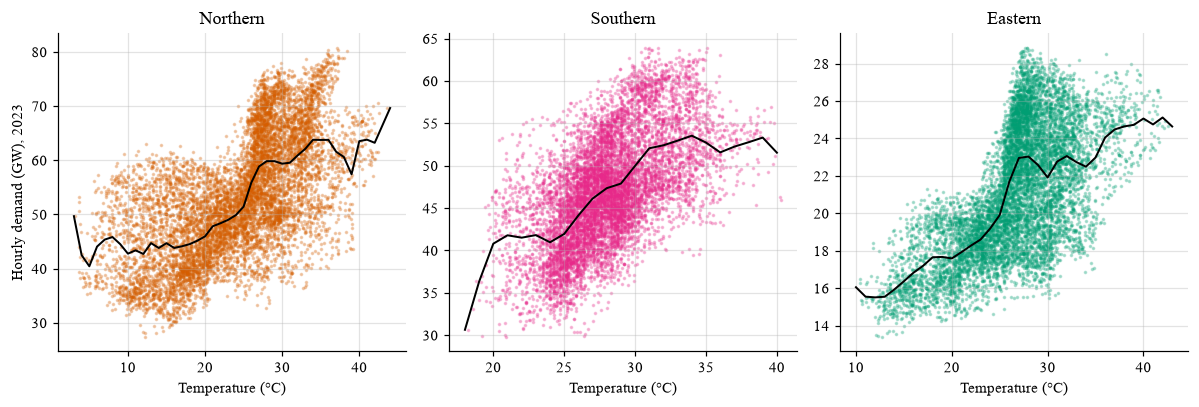

In [9]:
corr = {loc: g["demand_gw"].corr(g["temperature"]) for loc, g in df.groupby("location")}
print("Pearson correlation, demand vs temperature:", {k: round(float(corr[k]), 2) for k in REGIONS})

# Holiday effect: national daily demand on holidays vs non-holidays of the same weekday, month and year
nd = nat.groupby(nat["datetime"].dt.date).agg(
    demand=("demand_gw", "mean"), holiday=("is_holiday", "max"),
    dow=("day_of_week", "first"), month=("month", "first"))
nd["year"] = pd.to_datetime(nd.index).year
reference = nd[nd["holiday"] == 0].groupby(["year", "month", "dow"])["demand"].mean().rename("reference")
hol = nd[nd["holiday"] == 1].join(reference, on=["year", "month", "dow"])
print(f"Holiday / comparable non-holiday demand: {(hol['demand'] / hol['reference']).mean():.2f} ({len(hol)} holidays)")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, loc in zip(axes, ["Northern", "Southern", "Eastern"]):
    g = df[(df["location"] == loc) & (df["datetime"].dt.year == 2023)]
    ax.scatter(g["temperature"], g["demand_gw"], s=2, alpha=0.25, color=REGION_COLORS[loc])
    per_degree = g.groupby(g["temperature"].round())["demand_gw"].mean()
    ax.plot(per_degree.index, per_degree.values, color="black", lw=1.3)
    ax.set_title(loc)
    ax.set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Hourly demand (GW), 2023")
fig.tight_layout()
save(fig, "fig03_demand_vs_temperature.png")
plt.show()

## Chapter 4 — Figure 4: pipeline diagram

The diagram is drawn with matplotlib. Two labels differ from the earlier version of the figure: the demand source is given as the Kaggle dataset (Section 3.1 notes that the original provider is not stated), and the merged table is described as 280,368 rows in total (46,728 hours × 6 series).

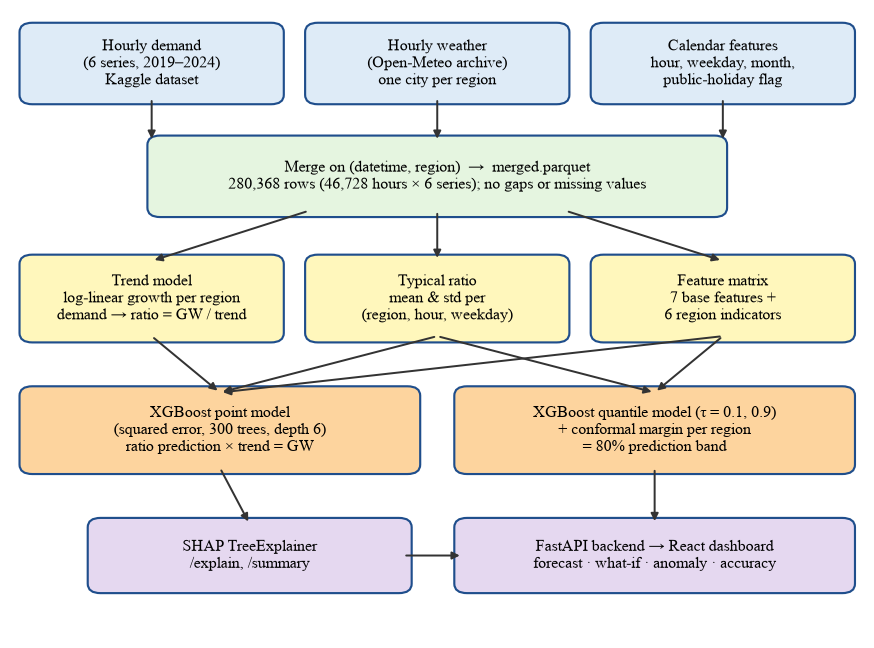

In [10]:
def box(ax, x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.01,rounding_size=0.015",
                                fc=color, ec="#1f4e8c", lw=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=10.5)

def arrow(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.3))

fig, ax = plt.subplots(figsize=(10, 7.4))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
blue, green, yellow, orange, purple = "#deebf7", "#e5f5e0", "#fff7bc", "#fdd49e", "#e5d8f0"

box(ax, 0.02, 0.86, 0.29, 0.11, "Hourly demand\n(6 series, 2019–2024)\nKaggle dataset", blue)
box(ax, 0.355, 0.86, 0.29, 0.11, "Hourly weather\n(Open-Meteo archive)\none city per region", blue)
box(ax, 0.69, 0.86, 0.29, 0.11, "Calendar features\nhour, weekday, month,\npublic-holiday flag", blue)
box(ax, 0.17, 0.68, 0.66, 0.11, "Merge on (datetime, region)  →  merged.parquet\n280,368 rows (46,728 hours × 6 series); no gaps or missing values", green)
box(ax, 0.02, 0.48, 0.29, 0.12, "Trend model\nlog-linear growth per region\ndemand → ratio = GW / trend", yellow)
box(ax, 0.355, 0.48, 0.29, 0.12, "Typical ratio\nmean & std per\n(region, hour, weekday)", yellow)
box(ax, 0.69, 0.48, 0.29, 0.12, "Feature matrix\n7 base features +\n6 region indicators", yellow)
box(ax, 0.02, 0.27, 0.45, 0.12, "XGBoost point model\n(squared error, 300 trees, depth 6)\nratio prediction × trend = GW", orange)
box(ax, 0.53, 0.27, 0.45, 0.12, "XGBoost quantile model (τ = 0.1, 0.9)\n+ conformal margin per region\n= 80% prediction band", orange)
box(ax, 0.1, 0.08, 0.36, 0.1, "SHAP TreeExplainer\n/explain, /summary", purple)
box(ax, 0.53, 0.08, 0.45, 0.1, "FastAPI backend → React dashboard\nforecast · what-if · anomaly · accuracy", purple)

for x in (0.165, 0.5, 0.835):
    arrow(ax, x, 0.86, x, 0.79)
for x in (0.165, 0.5, 0.835):
    arrow(ax, 0.5 + (x - 0.5) * 0.45, 0.68, x, 0.60)
for x1 in (0.165, 0.5, 0.835):
    arrow(ax, x1, 0.48, 0.245, 0.39)
for x1 in (0.5, 0.835):
    arrow(ax, x1, 0.48, 0.755, 0.39)
arrow(ax, 0.245, 0.27, 0.28, 0.18)
arrow(ax, 0.755, 0.27, 0.755, 0.18)
arrow(ax, 0.46, 0.13, 0.53, 0.13)
save(fig, "fig04_pipeline.png")
plt.show()

## Chapter 5 — Table 5 (backtest windows) and Table 8 (fitted growth trend)

In [11]:
rows = []
for i, (start, end) in enumerate(train.FOLDS, 1):
    rows.append({"window": i, "training rows": int((df["datetime"] < start).sum()),
                 "test period": f"{start} to {pd.Timestamp(end) - pd.Timedelta(days=1):%Y-%m-%d}",
                 "test rows": int(((df["datetime"] >= start) & (df["datetime"] < end)).sum())})
display(pd.DataFrame(rows))

levels = F.fit_levels(df)   # the final model's trend, fitted on all data
table8 = pd.DataFrame(levels, index=["slope a (per year)", "intercept b"]).T.loc[REGIONS]
table8["annual growth e^a - 1 (%)"] = (np.exp(table8["slope a (per year)"]) - 1) * 100
table8.round(4)

/var/folders/yc/xtxtly_j0rg671bddd4m674w0000gn/T/ipykernel_76283/4146918909.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  "test period": f"{start} to {pd.Timestamp(end) - pd.Timedelta(days=1):%Y-%m-%d}",


,window,training rows,test period,test rows
0,1,175104,2022-05-01 to 2022-10-31,26496
1,2,201600,2022-11-01 to 2023-04-30,26064
2,3,227664,2023-05-01 to 2023-10-31,26496
3,4,254160,2023-11-01 to 2024-04-30,26208


,slope a (per year),intercept b,annual growth e^a - 1 (%)
National,0.0562,4.9209,5.7840
Northern,0.0488,3.7205,5.0049
Western,0.0654,3.7359,6.7545
Eastern,0.0589,2.7515,6.0656
Southern,0.0537,3.5740,5.5154
North-Eastern,0.0429,0.5714,4.3803


## Chapter 6 — Results

### Rolling-origin backtest

`train.backtest` is the same function that `backend/train.py` runs. It fits every component on the data before each test window, predicts the window, and adds the three baselines. It returns the metrics and the out-of-sample predictions; it does not write any files. The cell after it checks that the metrics equal the committed `models/backtest_metrics.json`.

In [12]:
metrics, oos = train.backtest(df)
oos = oos.merge(df[["datetime", "location", "temperature", "is_holiday", "hour", "day_of_week", "month"]],
                on=["datetime", "location"])

committed = json.loads((ROOT / "models" / "backtest_metrics.json").read_text())
for key in ["summary", "folds", "band"]:
    print(f"{key:8s} identical to models/backtest_metrics.json: {metrics[key] == committed[key]}")

fold 1: 2022-05-01 to 2022-10-31  GridSense 6.97%  Original XGBoost 8.72%  Same hour last week 6.97%  Typical profile 15.86%
fold 2: 2022-11-01 to 2023-04-30  GridSense 6.32%  Original XGBoost 8.93%  Same hour last week 5.01%  Typical profile 11.9%
fold 3: 2023-05-01 to 2023-10-31  GridSense 7.66%  Original XGBoost 8.99%  Same hour last week 7.79%  Typical profile 19.51%
fold 4: 2023-11-01 to 2024-04-30  GridSense 7.53%  Original XGBoost 9.66%  Same hour last week 5.14%  Typical profile 12.51%
summary  identical to models/backtest_metrics.json: True
folds    identical to models/backtest_metrics.json: True
band     identical to models/backtest_metrics.json: True


### Table 9 (overall results) and Table 10 (WAPE by region)

In [13]:
MODELS = list(train.MODEL_COLUMNS)
table9 = pd.DataFrame({m: {"MAE (GW)": metrics["summary"][m]["mae_gw"], "WAPE (%)": metrics["summary"][m]["wape_pct"]}
                       for m in MODELS}).T
display(table9)
table10 = pd.DataFrame({m: metrics["summary"][m]["wape_by_location"] for m in MODELS}).loc[REGIONS]
table10

,MAE (GW),WAPE (%)
GridSense,3.76,7.12
Original XGBoost,4.35,9.07
Same hour last week,3.21,6.23
Typical profile,8.83,14.94


,GridSense,Original XGBoost,Same hour last week,Typical profile
National,5.43,6.49,4.40,13.77
Northern,7.02,8.51,7.77,17.05
Western,6.34,8.07,5.30,14.96
Eastern,7.95,7.16,6.42,15.80
Southern,8.29,8.09,5.96,14.34
North-Eastern,7.70,16.13,7.51,13.75


### Table 13 (WAPE per test window) and Table 14 (GridSense WAPE by region and window)

In [14]:
table13 = pd.DataFrame({f"W{i + 1}": {m: f["models"][m]["wape_pct"] for m in MODELS}
                        for i, f in enumerate(metrics["folds"])})
display(table13)
table14 = pd.DataFrame({f"Window {i + 1}": f["models"]["GridSense"]["wape_by_location"]
                        for i, f in enumerate(metrics["folds"])}).loc[REGIONS]
table14

,W1,W2,W3,W4
GridSense,6.97,6.32,7.66,7.53
Original XGBoost,8.72,8.93,8.99,9.66
Same hour last week,6.97,5.01,7.79,5.14
Typical profile,15.86,11.90,19.51,12.51


,Window 1,Window 2,Window 3,Window 4
National,5.31,4.61,7.39,4.42
Northern,8.57,5.35,6.43,7.74
Western,7.36,5.74,7.22,5.03
Eastern,7.97,5.98,6.18,11.66
Southern,6.23,8.61,12.05,6.28
North-Eastern,6.38,7.64,6.72,10.07


### Figure 5: held-out daily mean demand, actual versus GridSense

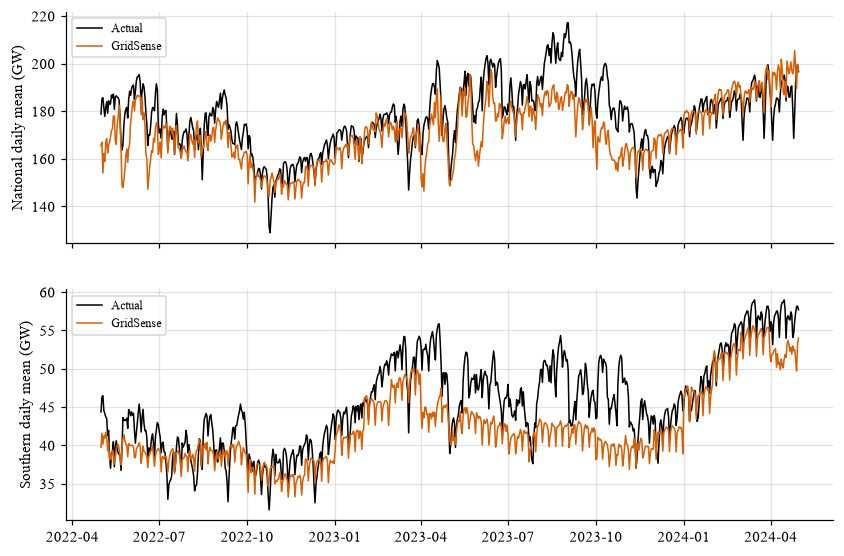

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax, loc in zip(axes, ["National", "Southern"]):
    series = pd.DataFrame(metrics["daily_series"][loc])
    series["date"] = pd.to_datetime(series["date"])
    ax.plot(series["date"], series["actual_gw"], color="black", lw=1, label="Actual")
    ax.plot(series["date"], series["predicted_gw"], color="#d95f02", lw=1, label="GridSense")
    ax.set_ylabel(f"{loc} daily mean (GW)")
    ax.legend(loc="upper left", fontsize=8)
save(fig, "fig05_actual_vs_predicted.png")
plt.show()

### Figure 6: training and held-out error per boosting round (window 4)

Held-out minimum 0.0909 at round 291; final training 0.0773, final held-out 0.0909


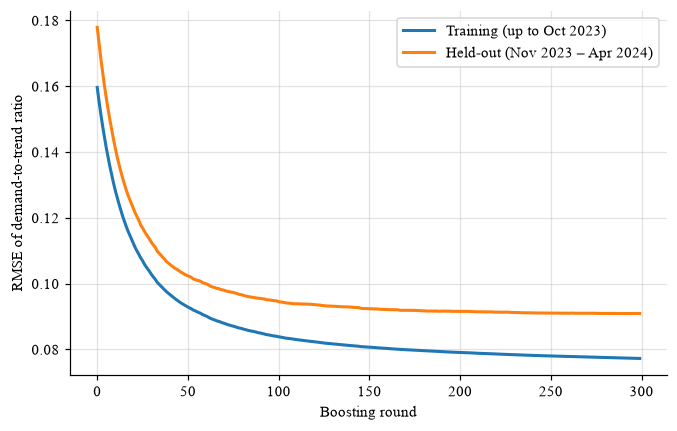

In [16]:
start, end = train.FOLDS[-1]
tr = df[df["datetime"] < start].copy()
te = df[(df["datetime"] >= start) & (df["datetime"] < end)].copy()
lv = F.fit_levels(tr)
for d in (tr, te):
    d["ratio"] = d["demand_gw"] / F.level_gw(d["location"], d["datetime"], lv)
stats = F.fit_ratio_stats(tr)
tr, te = train.add_typical_ratio(tr, stats), train.add_typical_ratio(te, stats)

curve_model = xgb.XGBRegressor(**train.XGB_PARAMS, eval_metric="rmse")
curve_model.fit(F.encode(tr), tr["ratio"], eval_set=[(F.encode(tr), tr["ratio"]), (F.encode(te), te["ratio"])], verbose=False)
curves = curve_model.evals_result()
train_rmse = np.array(curves["validation_0"]["rmse"])
test_rmse = np.array(curves["validation_1"]["rmse"])
print(f"Held-out minimum {test_rmse.min():.4f} at round {test_rmse.argmin() + 1}; "
      f"final training {train_rmse[-1]:.4f}, final held-out {test_rmse[-1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.plot(train_rmse, lw=2, label="Training (up to Oct 2023)")
ax.plot(test_rmse, lw=2, label="Held-out (Nov 2023 – Apr 2024)")
ax.set_xlabel("Boosting round")
ax.set_ylabel("RMSE of demand-to-trend ratio")
ax.legend()
save(fig, "fig06_learning_curve.png")
plt.show()

### Section 6.4: error analysis

WAPE is computed as in `train.error_metrics`: total absolute error divided by total actual demand within each region, then averaged over the six regions.

In [17]:
oos["abs_err"] = (oos["demand_gw"] - oos["predicted"]).abs()

def wape(frame, by=None):
    # Mean over regions of total |error| / total demand, optionally within groups
    keys = ([by] if isinstance(by, str) else list(by or [])) + ["location"]
    sums = frame.groupby(keys)[["abs_err", "demand_gw"]].sum()
    per_region = sums["abs_err"] / sums["demand_gw"] * 100
    return per_region.mean() if len(keys) == 1 else per_region.groupby(level=list(range(len(keys) - 1))).mean()

by_hour, by_month = wape(oos, "hour"), wape(oos, "month")
print(f"By hour: lowest {by_hour.idxmin():02d}:00 ({by_hour.min():.2f}%), highest {by_hour.idxmax():02d}:00 ({by_hour.max():.2f}%)")
print("By month:", by_month.round(2).to_dict())
by_holiday = wape(oos, "is_holiday")
print(f"Holiday hours {by_holiday[1]:.2f}% vs other hours {by_holiday[0]:.2f}%")
by_weekend = wape(oos.assign(weekend=oos["day_of_week"] >= 5), "weekend")
print(f"Weekday {by_weekend[False]:.2f}%, weekend {by_weekend[True]:.2f}%")
hot = oos["temperature"] >= oos.groupby("location")["temperature"].transform(lambda s: s.quantile(0.95))
print(f"Hottest 5% of hours per region: {wape(oos[hot]):.2f}%")

By hour: lowest 08:00 (6.26%), highest 15:00 (7.91%)
By month: {1: 5.91, 2: 6.06, 3: 6.49, 4: 10.05, 5: 7.84, 6: 7.56, 7: 5.84, 8: 7.52, 9: 7.04, 10: 8.39, 11: 6.65, 12: 6.22}
Holiday hours 8.53% vs other hours 7.03%
Weekday 7.14%, weekend 7.02%
Hottest 5% of hours per region: 8.21%


### Section 6.4: daily errors, worst days and Figure 7 (Eastern region, March–April 2024)

Median daily WAPE: {'Eastern': 6.8, 'National': 4.5, 'North-Eastern': 6.9, 'Northern': 5.7, 'Southern': 7.3, 'Western': 5.1}
99th percentile:   {'Eastern': 30.6, 'National': 15.3, 'North-Eastern': 21.4, 'Northern': 20.9, 'Southern': 21.0, 'Western': 18.6}

Ten worst region-days:


daily_wape  actual_mean  predicted_mean
location      date                                               
Eastern       2024-04-21        54.6         17.4            27.0
              2024-04-20        49.8         17.4            26.1
              2024-04-26        42.6         18.7            26.7
              2024-04-04        35.9         18.6            25.3
              2024-04-25        35.6         18.8            25.4
North-Eastern 2022-10-25        35.4          1.5             2.0
Eastern       2024-04-22        35.3         19.2            25.9
              2024-04-05        35.1         19.2            26.0
Northern      2024-04-25        34.3         40.1            53.8
North-Eastern 2024-04-26        34.2          1.7             2.3

Eastern, 20-21 April 2024:


,actual_mean,predicted_mean,temperature_mean
date,,,
2024-04-20,17.4,26.1,32.9
2024-04-21,17.4,27.0,33.6


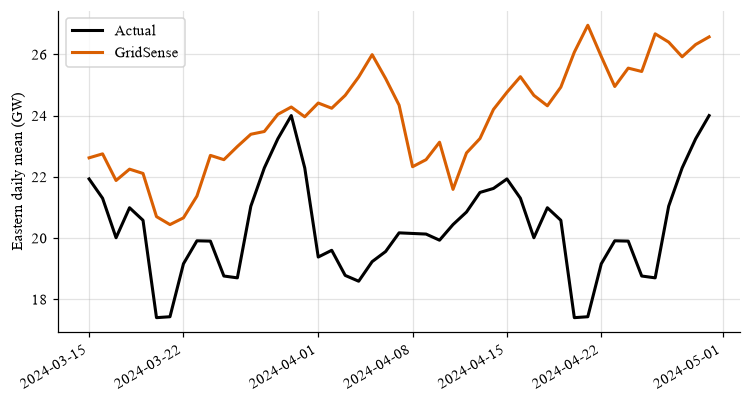

In [18]:
oos["date"] = oos["datetime"].dt.date
day = oos.groupby(["location", "date"])[["abs_err", "demand_gw", "predicted", "temperature"]].agg(
    {"abs_err": "sum", "demand_gw": ["sum", "mean"], "predicted": "mean", "temperature": "mean"})
day.columns = ["abs_err", "demand_sum", "actual_mean", "predicted_mean", "temperature_mean"]
day["daily_wape"] = day["abs_err"] / day["demand_sum"] * 100

print("Median daily WAPE:", day.groupby(level=0)["daily_wape"].median().round(1).to_dict())
print("99th percentile:  ", day.groupby(level=0)["daily_wape"].quantile(0.99).round(1).to_dict())
print("\nTen worst region-days:")
display(day.sort_values("daily_wape", ascending=False).head(10)[["daily_wape", "actual_mean", "predicted_mean"]].round(1))
print("Eastern, 20-21 April 2024:")
display(day.loc["Eastern"].loc[pd.to_datetime(["2024-04-20", "2024-04-21"]).date,
                               ["actual_mean", "predicted_mean", "temperature_mean"]].round(1))

eastern = pd.DataFrame(metrics["daily_series"]["Eastern"])
eastern["date"] = pd.to_datetime(eastern["date"])
eastern = eastern[eastern["date"] >= "2024-03-15"]
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.plot(eastern["date"], eastern["actual_gw"], color="black", lw=2, label="Actual")
ax.plot(eastern["date"], eastern["predicted_gw"], color="#d95f02", lw=2, label="GridSense")
ax.set_ylabel("Eastern daily mean (GW)")
ax.legend()
fig.autofmt_xdate()
save(fig, "fig07_eastern_march_april_2024.png")
plt.show()

### Section 6.4: bias (actual minus forecast, as a percentage of actual demand)

In [19]:
oos["err"] = oos["demand_gw"] - oos["predicted"]
def bias(frame, keys):
    sums = frame.groupby(keys)[["err", "demand_gw"]].sum()
    return sums["err"] / sums["demand_gw"] * 100

print("Whole backtest:", bias(oos, "location").loc[REGIONS].round(2).to_dict())
display(bias(oos, ["location", "fold"]).unstack().loc[REGIONS].rename(columns=lambda f: f"Window {f + 1}").round(1))
south_w3 = oos[(oos["location"] == "Southern") & (oos["fold"] == 2)]
print(f"Southern, window 3: mean actual {south_w3['demand_gw'].mean():.1f} GW, mean forecast {south_w3['predicted'].mean():.1f} GW")

Whole backtest: {'National': 3.31, 'Northern': 1.86, 'Western': 2.42, 'Eastern': -0.64, 'Southern': 6.95, 'North-Eastern': -2.35}


fold,Window 1,Window 2,Window 3,Window 4
location,,,,
National,4.3,2.9,7.1,-1.4
Northern,7.0,-0.8,3.8,-4.4
Western,2.7,4.2,5.2,-2.3
Eastern,7.4,-3.7,2.7,-11.5
Southern,3.1,7.4,11.7,5.0
North-Eastern,2.5,-6.4,2.0,-9.6


Southern, window 3: mean actual 47.1 GW, mean forecast 41.6 GW


### Section 6.5.1 and Table 11: prediction band coverage

In [20]:
print("Raw band coverage, all windows:", train.coverage(oos), "%")
print("Raw band coverage per window:", [train.coverage(oos[oos["fold"] == k]) for k in range(4)])

margins = train.conformal_margins(oos[oos["fold"] < 3])   # margins from windows 1-3
window4 = oos[oos["fold"] == 3]
print("Calibrated coverage, window 4:", train.coverage(window4, margins), "%")
pd.Series({loc: train.coverage(window4[window4["location"] == loc], margins) for loc in REGIONS},
          name="Table 11: coverage in window 4 (%)").to_frame().T

Raw band coverage, all windows: 71.2 %
Raw band coverage per window: [75.7, 71.0, 69.6, 68.6]
Calibrated coverage, window 4: 78.4 %


,National,Northern,Western,Eastern,Southern,North-Eastern
Table 11: coverage in window 4 (%),86.4,80.3,88.6,58.0,84.7,72.2


### Section 6.4: effect of the repeated April 2024 data

Demand for April 2024 repeats March 2024 (Section 3.3 check above). This cell recomputes the backtest summary with April 2024 left out of window 4, and the band coverage of window 4 without April, to show how much the defect affects the reported results. The figures quoted in the report are those computed on the data as distributed.

In [21]:
april_2024 = oos["datetime"] >= "2024-04-01"
rows = {}
for name, column in train.MODEL_COLUMNS.items():
    per_window = []
    for k in range(4):
        f = oos[(oos["fold"] == k) & ~april_2024]
        sums = f.assign(e=(f["demand_gw"] - f[column]).abs()).groupby("location")[["e", "demand_gw"]].sum()
        per_window.append((sums["e"] / sums["demand_gw"] * 100).mean())
    rows[name] = {"WAPE as reported (%)": metrics["summary"][name]["wape_pct"],
                  "WAPE without Apr 2024 (%)": round(float(np.mean(per_window)), 2),
                  "Window 4 as reported (%)": metrics["folds"][3]["models"][name]["wape_pct"],
                  "Window 4 without Apr 2024 (%)": round(float(per_window[3]), 2)}
display(pd.DataFrame(rows).T)

w4_clean = oos[(oos["fold"] == 3) & ~april_2024]
print("Calibrated coverage, window 4 without April 2024:", train.coverage(w4_clean, margins), "%")
print({loc: train.coverage(w4_clean[w4_clean["location"] == loc], margins) for loc in REGIONS})

,WAPE as reported (%),WAPE without Apr 2024 (%),Window 4 as reported (%),Window 4 without Apr 2024 (%)
GridSense,7.12,6.88,7.53,6.56
Original XGBoost,9.07,9.01,9.66,9.40
Same hour last week,6.23,6.14,5.14,4.80
Typical profile,14.94,14.82,12.51,12.04


Calibrated coverage, window 4 without April 2024: 78.3 %
{'National': 87.0, 'Northern': 84.1, 'Western': 86.3, 'Eastern': 55.5, 'Southern': 87.9, 'North-Eastern': 68.9}


### Section 6.5.2 and Table 12: ablation study

Each variant uses the point model only, with the same windows, hyperparameters and seed. "Without trend" predicts raw GW without the year; in place of the typical ratio it uses the typical demand in GW for the region, hour and weekday, as the project's first model did.

In [22]:
def ablation(drop=(), trend=True):
    results = []
    for start, end in train.FOLDS:
        tr = df[df["datetime"] < start].copy()
        te = df[(df["datetime"] >= start) & (df["datetime"] < end)].copy()
        if trend:
            lv = F.fit_levels(tr)
            tr["ratio"] = tr["demand_gw"] / F.level_gw(tr["location"], tr["datetime"], lv)
            stats = F.fit_ratio_stats(tr)
            tr, te = train.add_typical_ratio(tr, stats), train.add_typical_ratio(te, stats)
            model = xgb.XGBRegressor(**train.XGB_PARAMS).fit(F.encode(tr).drop(columns=list(drop)), tr["ratio"])
            pred = model.predict(F.encode(te).drop(columns=list(drop))) * F.level_gw(te["location"], te["datetime"], lv)
        else:
            profile = tr.groupby(F.PROFILE_KEY)["demand_gw"].mean().rename("typical_ratio").reset_index()
            tr, te = tr.merge(profile, on=F.PROFILE_KEY), te.merge(profile, on=F.PROFILE_KEY)
            model = xgb.XGBRegressor(**train.XGB_PARAMS).fit(F.encode(tr), tr["demand_gw"])
            pred = model.predict(F.encode(te))
        results.append(train.error_metrics(te["demand_gw"].reset_index(drop=True), pd.Series(pred),
                                           te["location"].reset_index(drop=True)))
    return {"MAE (GW)": round(np.mean([r["mae_gw"] for r in results]), 2),
            "WAPE (%)": round(np.mean([r["wape_pct"] for r in results]), 2),
            "Southern WAPE (%)": round(np.mean([r["wape_by_location"]["Southern"] for r in results]), 2)}

variants = {
    "Full GridSense": {},
    "Without weather (temperature, humidity)": {"drop": ("temperature", "humidity")},
    "Without typical ratio": {"drop": ("typical_ratio",)},
    "Without holiday flag": {"drop": ("is_holiday",)},
    "Without month": {"drop": ("month",)},
    "Without trend (raw GW target, no year)": {"trend": False},
}
table12 = pd.DataFrame({name: ablation(**kw) for name, kw in variants.items()}).T
table12["Δ WAPE"] = (table12["WAPE (%)"] - table12.loc["Full GridSense", "WAPE (%)"]).round(2)
table12

,MAE (GW),WAPE (%),Southern WAPE (%),Δ WAPE
Full GridSense,3.76,7.12,8.29,0.00
"Without weather (temperature, humidity)",4.00,7.73,8.63,0.61
Without typical ratio,3.80,7.17,8.36,0.05
Without holiday flag,3.77,7.11,8.31,-0.01
Without month,4.09,7.73,10.14,0.61
"Without trend (raw GW target, no year)",8.50,14.76,14.06,7.64


## Chapter 7 — Explainability (Figures 8 and 9)

SHAP values are computed for the deployed point model in `models/point_model.json`, which `backend/train.py` fits on all the data. Global importance uses 5,000 hours sampled from window 4 with seed 42. Region indicators are excluded, as in the API, because the user has already chosen the region.

Share of mean |SHAP| (%): {'temperature': 35.8, 'typical_ratio': 31.6, 'month': 16.6, 'hour': 10.5, 'humidity': 3.4, 'day_of_week': 1.1, 'is_holiday': 1.0}


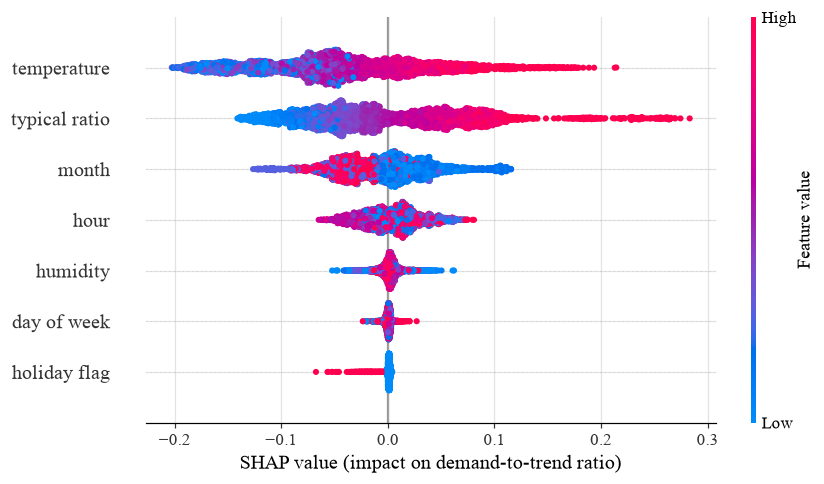

In [23]:
point_model = xgb.XGBRegressor()
point_model.load_model(ROOT / "models" / "point_model.json")
meta = json.loads((ROOT / "models" / "model_meta.json").read_text())
typical_stats = pd.read_parquet(ROOT / "data" / "processed" / "typical_stats.parquet")
explainer = shap.TreeExplainer(point_model)
LABELS = {"temperature": "temperature", "humidity": "humidity", "hour": "hour", "day_of_week": "day of week",
          "month": "month", "is_holiday": "holiday flag", "typical_ratio": "typical ratio"}

start, end = train.FOLDS[-1]
window4_rows = train.add_typical_ratio(df[(df["datetime"] >= start) & (df["datetime"] < end)], typical_stats)
sample = F.encode(window4_rows).sample(5000, random_state=SEED)
sv = explainer.shap_values(sample)
base_idx = [sample.columns.get_loc(c) for c in F.BASE_FEATURES]
mean_abs = pd.Series(np.abs(sv[:, base_idx]).mean(axis=0), index=F.BASE_FEATURES)
print("Share of mean |SHAP| (%):", (mean_abs / mean_abs.sum() * 100).astype(float).sort_values(ascending=False).round(1).to_dict())

shap.summary_plot(sv[:, base_idx], sample[F.BASE_FEATURES], feature_names=[LABELS[c] for c in F.BASE_FEATURES],
                  show=False, plot_size=(8, 4.5))
fig = plt.gcf()
plt.xlabel("SHAP value (impact on demand-to-trend ratio)")
save(fig, "fig08_shap_summary.png")
plt.show()

Northern 2024-03-15 14:00: 27.2 °C, 23% humidity; base 1.008 -> ratio 0.913; trend 53.2 GW -> forecast 48.6 GW, actual 52.2 GW
   {'temperature': -0.001, 'humidity': 0.024, 'hour': -0.053, 'day of week': -0.003, 'month': -0.021, 'holiday flag': 0.001, 'typical ratio': 0.04}
Northern 2023-06-12 15:00: 40.9 °C, 26% humidity; base 1.008 -> ratio 1.341; trend 51.3 GW -> forecast 68.8 GW, actual 70.0 GW
   {'temperature': 0.271, 'humidity': -0.003, 'hour': -0.036, 'day of week': 0.003, 'month': 0.021, 'holiday flag': 0.001, 'typical ratio': 0.012}


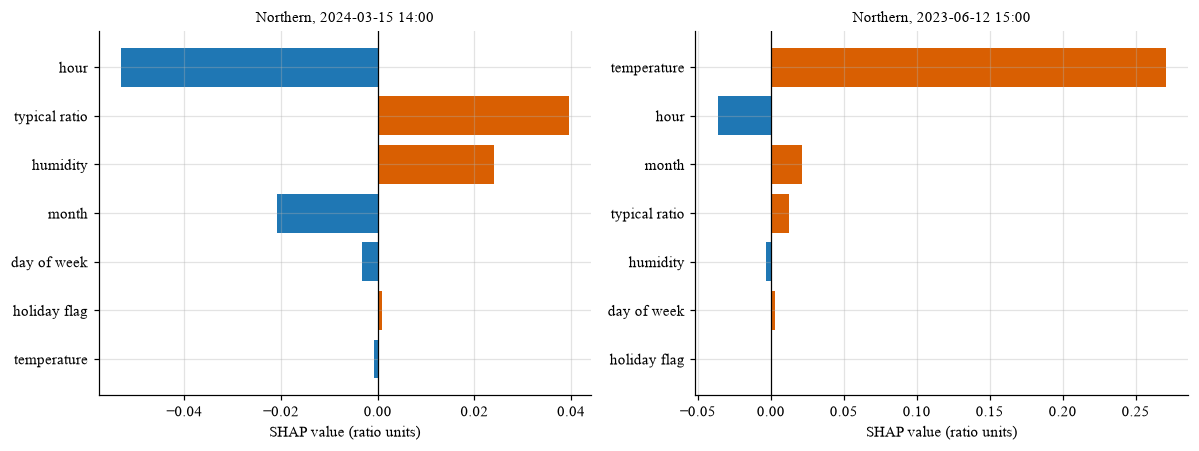

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, when in zip(axes, ["2024-03-15 14:00", "2023-06-12 15:00"]):
    row = train.add_typical_ratio(df[(df["location"] == "Northern") & (df["datetime"] == when)], typical_stats)
    x = F.encode(row)
    values = pd.Series(explainer.shap_values(x)[0][base_idx], index=[LABELS[c] for c in F.BASE_FEATURES])
    ratio = float(point_model.predict(x)[0])
    level = float(F.level_gw(row["location"], row["datetime"], meta["levels"])[0])
    print(f"Northern {when}: {row['temperature'].iloc[0]} °C, {row['humidity'].iloc[0]}% humidity; "
          f"base {float(explainer.expected_value):.3f} -> ratio {ratio:.3f}; trend {level:.1f} GW -> "
          f"forecast {ratio * level:.1f} GW, actual {row['demand_gw'].iloc[0]:.1f} GW")
    print("  ", values.astype(float).round(3).to_dict())
    values = values.reindex(values.abs().sort_values().index)
    ax.barh(values.index, values.values, color=np.where(values.values >= 0, "#d95f02", "#1f77b4"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Northern, {when}", fontsize=10)
    ax.set_xlabel("SHAP value (ratio units)")
fig.tight_layout()
save(fig, "fig09_shap_local.png")
plt.show()

## Saved figures

| File | Report figure |
| --- | --- |
| `fig01_national_daily_demand.png` | Figure 1 |
| `fig02_hourly_profiles.png` | Figure 2 |
| `fig03_demand_vs_temperature.png` | Figure 3 |
| `fig04_pipeline.png` | Figure 4 |
| `fig05_actual_vs_predicted.png` | Figure 5 |
| `fig06_learning_curve.png` | Figure 6 |
| `fig07_eastern_march_april_2024.png` | Figure 7 |
| `fig08_shap_summary.png` | Figure 8 |
| `fig09_shap_local.png` | Figure 9 |